# Red neuronal feedforward desde cero: clasificación de MNIST
**Alumno:** Junior Arturo Vázquez Leonel · **Matrícula:** 2430319  
**Asignatura:** Fundamentos de Inteligencia Artificial · Unidad 1

Desarrollo del [taller de Diego R. Ibarra](https://github.com/DiegoRIbarra/TallerSaid/blob/main/Taller.md).
Construimos una red **784 → 100 → 10** con NumPy: entrada de píxeles, capa oculta ReLU con dropout y salida lineal. La clase se decide con `argmax`; sus puntuaciones no son probabilidades.

Se utilizan las primeras **1,000 imágenes de entrenamiento**, las **10,000 de prueba**, 100 épocas, tasa de aprendizaje 0.005 y semilla 1. No se usan TensorFlow ni PyTorch. Los resultados de este documento se calculan al ejecutar sus celdas, sin adoptar como propios los valores ilustrativos de la guía.

## 1. Entorno e hiperparámetros
La semilla permite repetir las decisiones aleatorias. La red no tiene términos de sesgo, siguiendo la arquitectura del taller. El dropout desactiva aproximadamente la mitad de las neuronas ocultas durante entrenamiento y escala las restantes por dos; durante evaluación se utiliza toda la capa sin dropout.

In [1]:
from pathlib import Path
from urllib.request import urlretrieve
import gzip
import struct
import json
import platform
import time
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

DATA_DIR = Path("datos")
OUTPUT_DIR = Path("resultados")
DATA_DIR.mkdir(exist_ok=True)
OUTPUT_DIR.mkdir(exist_ok=True)
SEED = 1
SAMPLE = 1000
EPOCHS = 100
LEARNING_RATE = 0.005
HIDDEN_SIZE = 100
KEEP_PROBABILITY = 0.5
print("Python:", platform.python_version())
print("NumPy:", np.__version__, "Matplotlib:", matplotlib.__version__)
print(f"Arquitectura: 784 → {HIDDEN_SIZE} → 10; épocas: {EPOCHS}; muestra: {SAMPLE}")

Python: 3.14.8
NumPy: 2.5.2 Matplotlib: 3.11.1
Arquitectura: 784 → 100 → 10; épocas: 100; muestra: 1000


## 2. Descarga y lectura de MNIST
Cada imagen tiene 28 × 28 píxeles de intensidad entre 0 y 255. Los archivos IDX comprimidos incluyen un encabezado: validamos su identificador y dimensiones antes de interpretarlos como arreglos. La descarga solo se realiza si falta el archivo local.

In [2]:
BASE_URL = "https://ossci-datasets.s3.amazonaws.com/mnist/"
FILENAMES = {
    "train_images": "train-images-idx3-ubyte.gz",
    "train_labels": "train-labels-idx1-ubyte.gz",
    "test_images": "t10k-images-idx3-ubyte.gz",
    "test_labels": "t10k-labels-idx1-ubyte.gz",
}
for filename in FILENAMES.values():
    destination = DATA_DIR / filename
    if not destination.exists():
        print("Descargando", filename)
        temporary = destination.with_suffix(".part")
        urlretrieve(BASE_URL + filename, temporary)
        temporary.replace(destination)

def read_idx(filename):
    with gzip.open(DATA_DIR / filename, "rb") as source:
        magic, count = struct.unpack(">II", source.read(8))
        if magic == 2051:
            rows, cols = struct.unpack(">II", source.read(8))
            assert (rows, cols) == (28, 28)
            return np.frombuffer(source.read(), dtype=np.uint8).reshape(count, rows * cols)
        if magic == 2049:
            return np.frombuffer(source.read(), dtype=np.uint8).reshape(count)
        raise ValueError(f"Formato IDX inesperado: {magic}")

x_train, y_train = read_idx(FILENAMES["train_images"]), read_idx(FILENAMES["train_labels"])
x_test, y_test = read_idx(FILENAMES["test_images"]), read_idx(FILENAMES["test_labels"])
assert x_train.shape == (60000, 784) and y_train.shape == (60000,)
assert x_test.shape == (10000, 784) and y_test.shape == (10000,)
print("Entrenamiento:", x_train.shape, y_train.shape)
print("Prueba:", x_test.shape, y_test.shape)
print("Tipo original:", x_train.dtype)
print("Etiqueta de la última imagen de entrenamiento:", y_train[-1])

Entrenamiento: (60000, 784) (60000,)
Prueba: (10000, 784) (10000,)
Tipo original: uint8
Etiqueta de la última imagen de entrenamiento: 8


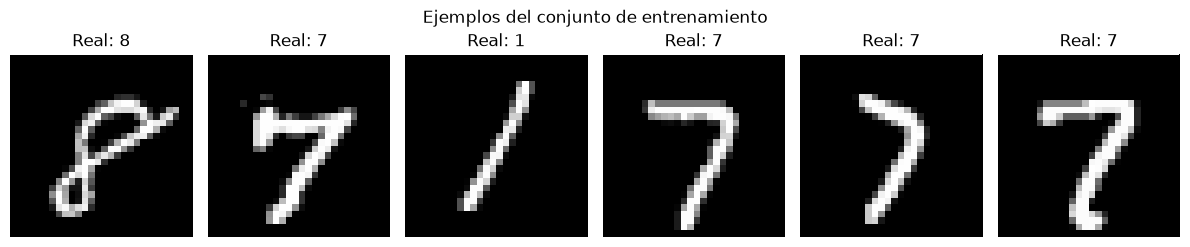

In [3]:
fig, axes = plt.subplots(1, 6, figsize=(12, 2.5))
indices = [59999, *np.random.default_rng(0).choice(len(x_train), size=5, replace=False)]
for axis, index in zip(axes, indices):
    axis.imshow(x_train[index].reshape(28, 28), cmap="gray")
    axis.set_title(f"Real: {y_train[index]}")
    axis.axis("off")
fig.suptitle("Ejemplos del conjunto de entrenamiento")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "muestras_mnist.png", dpi=150)
plt.show()

## 3. Normalización y etiquetas one-hot
Dividimos los píxeles entre 255 para obtener valores en [0, 1]. Cada etiqueta se convierte en un vector de diez componentes; por ejemplo, el dígito 5 activa la sexta posición. Solo las primeras 1,000 imágenes participan en las actualizaciones de pesos. El conjunto de prueba permanece separado.

In [4]:
training_images = x_train[:SAMPLE].astype(np.float64) / 255.0
test_images = x_test.astype(np.float64) / 255.0

def one_hot_encoding(labels):
    return (labels[:, None] == np.arange(10)[None, :]).astype(np.float64)

training_labels = one_hot_encoding(y_train[:SAMPLE])
test_labels = one_hot_encoding(y_test)
assert np.all(training_labels.sum(axis=1) == 1)
assert training_images.min() >= 0 and training_images.max() <= 1
print("Imágenes normalizadas:", training_images.shape, training_images.dtype)
for label, vector in zip(y_train[:3], training_labels[:3]):
    print(f"Dígito {label}: {vector}")

Imágenes normalizadas: (1000, 784) float64
Dígito 5: [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]
Dígito 0: [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Dígito 4: [0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]


## 4. Propagación y aprendizaje
La capa oculta calcula $h=\max(0,xW_1)$. Durante entrenamiento se aplica una máscara $m$ con valores 0 o 1 y se obtiene $\tilde h=h m / 0.5$. La salida es $s=\tilde h W_2$.

Usamos descenso de gradiente por ejemplo sobre $L=\frac{1}{2}\sum_k(s_k-y_k)^2$. Para comparar las curvas con el taller, reportamos la **suma de errores cuadrados por imagen**, equivalente a $2L$; no es el promedio sobre las diez salidas. Los gradientes se calculan antes de actualizar ambas matrices.

La derivada del dropout incluye el mismo factor de escala que la pasada hacia adelante. La guía omite ese factor en el gradiente oculto; aquí se incluye para que la retropropagación corresponda a la función implementada. Por este ajuste, las métricas no tienen que coincidir con sus ejemplos.

In [5]:
rng = np.random.RandomState(SEED)
weights_1 = rng.uniform(-0.1, 0.1, size=(784, HIDDEN_SIZE))
weights_2 = rng.uniform(-0.1, 0.1, size=(HIDDEN_SIZE, 10))

def relu(values):
    return np.maximum(0, values)

def predict_scores(images):
    return relu(images @ weights_1) @ weights_2

def evaluate(images, labels):
    scores = predict_scores(images)
    loss = np.mean(np.sum((scores - labels) ** 2, axis=1))
    accuracy = np.mean(scores.argmax(axis=1) == labels.argmax(axis=1))
    return float(loss), float(accuracy)

print("Matrices de pesos:", weights_1.shape, weights_2.shape)

Matrices de pesos: (784, 100) (100, 10)


## 5. Entrenamiento: 100 épocas
En cada época se recorren las 1,000 imágenes y se ajustan los pesos. Al terminar se evalúan entrenamiento y prueba sin dropout, con los mismos pesos finales de la época; así sus métricas son comparables. La evaluación de prueba se calcula en forma matricial para reducir el tiempo, sin modificar los pesos.

Las curvas de prueba se muestran para seguir el ejercicio de la guía. No se emplean para elegir otra arquitectura ni la mejor época: se reporta la época 100 fijada de antemano. Un experimento de selección de hiperparámetros requeriría un conjunto de validación adicional.

In [6]:
history = []
start_time = time.perf_counter()
for epoch in range(1, EPOCHS + 1):
    for image, target in zip(training_images, training_labels):
        hidden = relu(image @ weights_1)
        mask = rng.randint(0, 2, size=hidden.shape)
        dropout_scale = mask / KEEP_PROBABILITY
        hidden_dropout = hidden * dropout_scale
        scores = hidden_dropout @ weights_2
        output_gradient = scores - target
        hidden_gradient = (weights_2 @ output_gradient) * (hidden > 0) * dropout_scale
        weights_2 -= LEARNING_RATE * np.outer(hidden_dropout, output_gradient)
        weights_1 -= LEARNING_RATE * np.outer(image, hidden_gradient)
    train_loss, train_accuracy = evaluate(training_images, training_labels)
    test_loss, test_accuracy = evaluate(test_images, test_labels)
    assert np.isfinite([train_loss, test_loss]).all(), "El entrenamiento divergió"
    history.append([epoch, train_loss, train_accuracy, test_loss, test_accuracy])
    if epoch == 1 or epoch % 10 == 0:
        print(f"Época {epoch:3d}: SSE train={train_loss:.4f}, acierto train={train_accuracy:.2%}; "
              f"SSE prueba={test_loss:.4f}, acierto prueba={test_accuracy:.2%}")
elapsed_seconds = time.perf_counter() - start_time
history = np.asarray(history)
np.savetxt(OUTPUT_DIR / "historial.csv", history, delimiter=",", comments="",
           header="epoca,sse_entrenamiento,exactitud_entrenamiento,sse_prueba,exactitud_prueba")
np.savez_compressed(OUTPUT_DIR / "pesos_fnn.npz", weights_1=weights_1, weights_2=weights_2)
print(f"Tiempo de entrenamiento y evaluación: {elapsed_seconds:.1f} segundos")

Época   1: SSE train=0.5430, acierto train=75.90%; SSE prueba=0.6042, acierto prueba=66.30%


Época  10: SSE train=0.2125, acierto train=94.40%; SSE prueba=0.3362, acierto prueba=84.78%


Época  20: SSE train=0.1539, acierto train=97.10%; SSE prueba=0.3008, acierto prueba=86.93%


Época  30: SSE train=0.1284, acierto train=98.40%; SSE prueba=0.2928, acierto prueba=87.48%


Época  40: SSE train=0.1043, acierto train=99.10%; SSE prueba=0.2848, acierto prueba=87.44%


Época  50: SSE train=0.0988, acierto train=99.20%; SSE prueba=0.2914, acierto prueba=87.43%


Época  60: SSE train=0.0846, acierto train=99.70%; SSE prueba=0.2775, acierto prueba=88.52%


Época  70: SSE train=0.0738, acierto train=99.60%; SSE prueba=0.2763, acierto prueba=87.89%


Época  80: SSE train=0.0685, acierto train=99.60%; SSE prueba=0.2803, acierto prueba=87.78%


Época  90: SSE train=0.0695, acierto train=99.70%; SSE prueba=0.2816, acierto prueba=88.29%


Época 100: SSE train=0.0611, acierto train=99.80%; SSE prueba=0.2763, acierto prueba=87.82%
Tiempo de entrenamiento y evaluación: 22.5 segundos


## 6. Curvas de aprendizaje
El panel izquierdo muestra el error cuadrático por imagen y el derecho la proporción de aciertos. La serie de prueba utiliza sus propias métricas, corrigiendo la referencia equivocada a los valores de entrenamiento en la gráfica de la guía. Una diferencia entre las curvas permite explorar la generalización, pero por sí sola no demuestra el efecto del dropout; para medirlo se necesitaría un experimento comparativo.

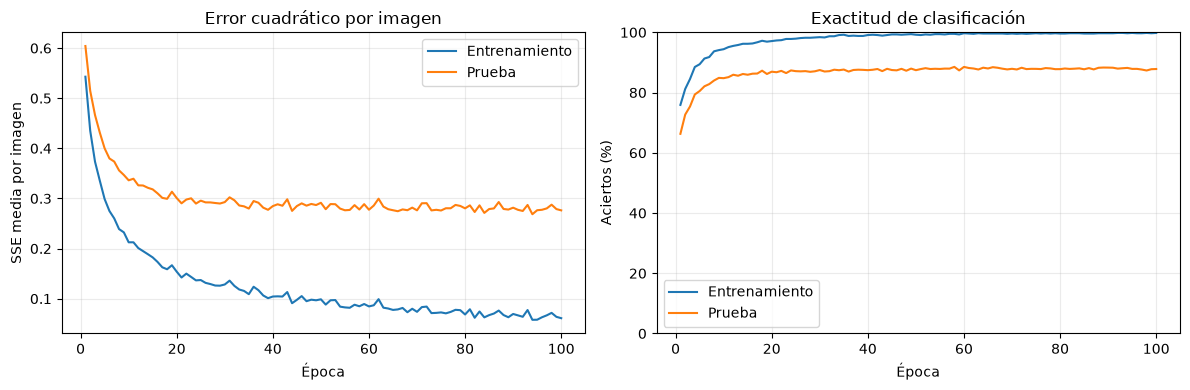

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history[:, 0], history[:, 1], label="Entrenamiento")
axes[0].plot(history[:, 0], history[:, 3], label="Prueba")
axes[0].set(title="Error cuadrático por imagen", xlabel="Época", ylabel="SSE media por imagen")
axes[1].plot(history[:, 0], history[:, 2] * 100, label="Entrenamiento")
axes[1].plot(history[:, 0], history[:, 4] * 100, label="Prueba")
axes[1].set(title="Exactitud de clasificación", xlabel="Época", ylabel="Aciertos (%)", ylim=(0, 100))
for axis in axes:
    axis.legend()
    axis.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "curvas_aprendizaje.png", dpi=150)
plt.show()

## 7. Predicciones y matriz de confusión
Probamos la imagen de índice 42 y nueve imágenes elegidas con una semilla independiente. Durante inferencia no se aplica dropout. La matriz de confusión cuenta los aciertos en la diagonal y los errores entre pares de clases fuera de ella.

Imagen 42: predicción=4, etiqueta real=4
Puntuaciones (no probabilidades): [-0.003  0.024 -0.001 -0.001  0.531  0.004 -0.002  0.04   0.057  0.221]


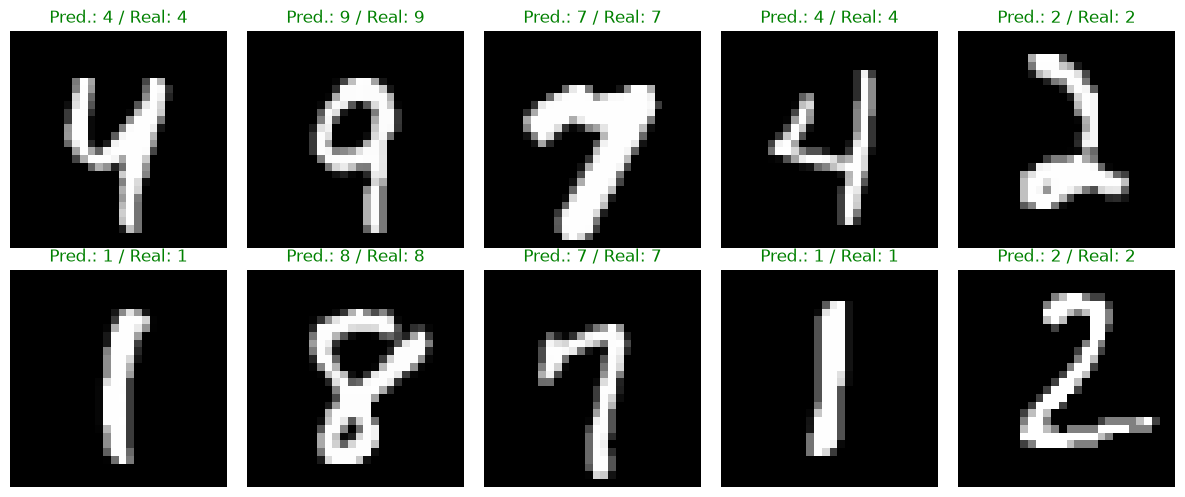

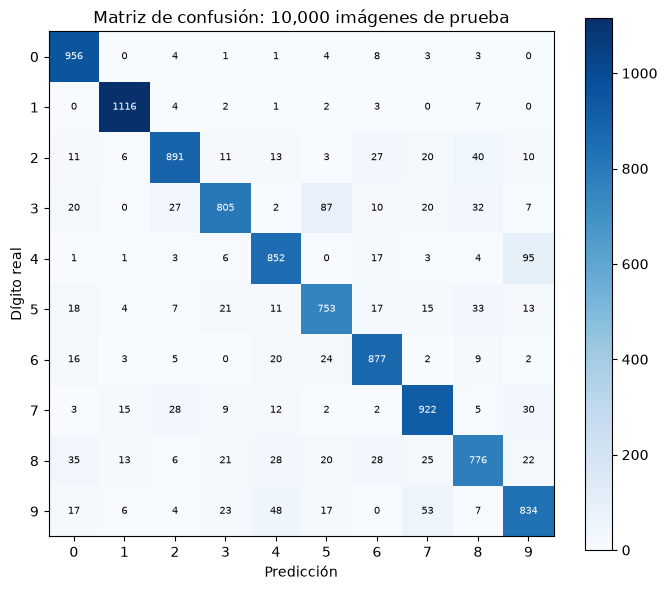

In [8]:
def predecir_digito(vector_imagen_784):
    vector = np.asarray(vector_imagen_784, dtype=np.float64)
    if vector.shape != (784,) or not np.isfinite(vector).all() or vector.min() < 0 or vector.max() > 1:
        raise ValueError("Se necesita un vector de 784 píxeles normalizados en [0, 1]")
    scores = predict_scores(vector)
    return int(scores.argmax()), scores

prediction, scores = predecir_digito(test_images[42])
print(f"Imagen 42: predicción={prediction}, etiqueta real={y_test[42]}")
print("Puntuaciones (no probabilidades):", np.round(scores, 3))
indices = np.concatenate(([42], np.random.default_rng(42).choice(len(test_images), size=9, replace=False)))
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for axis, index in zip(axes.flat, indices):
    predicted, _ = predecir_digito(test_images[index])
    axis.imshow(test_images[index].reshape(28, 28), cmap="gray")
    axis.set_title(f"Pred.: {predicted} / Real: {y_test[index]}",
                   color="green" if predicted == y_test[index] else "red")
    axis.axis("off")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "predicciones.png", dpi=150)
plt.show()

predictions = predict_scores(test_images).argmax(axis=1)
confusion = np.zeros((10, 10), dtype=int)
np.add.at(confusion, (y_test, predictions), 1)
assert confusion.sum() == len(y_test)
assert np.isclose(np.trace(confusion) / len(y_test), history[-1, 4])
np.savetxt(OUTPUT_DIR / "matriz_confusion.csv", confusion, fmt="%d", delimiter=",")
fig, axis = plt.subplots(figsize=(7, 6))
image = axis.imshow(confusion, cmap="Blues")
for real in range(10):
    for predicted in range(10):
        value = confusion[real, predicted]
        axis.text(predicted, real, str(value), ha="center", va="center", fontsize=7,
                  color="white" if value > confusion.max() / 2 else "black")
axis.set(xticks=range(10), yticks=range(10), xlabel="Predicción", ylabel="Dígito real",
         title="Matriz de confusión: 10,000 imágenes de prueba")
fig.colorbar(image, ax=axis)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "matriz_confusion.png", dpi=150)
plt.show()

## 8. Imagen propia (opcional)
La guía propone clasificar un dibujo adicional. La función siguiente acepta una imagen, la convierte a escala de grises y la redimensiona a 28 × 28. Para un dibujo negro sobre fondo blanco se usa `invertir=True`. Se debe procurar que el dígito esté centrado y tenga márgenes parecidos a MNIST.

No se incluye un dibujo personal del alumno y esta prueba se deja identificada como opcional. Las imágenes de MNIST de la sección anterior sí se evalúan. Una fotografía o un dibujo fuera de la distribución de entrenamiento puede fallar incluso si tiene la resolución correcta.

In [9]:
from PIL import Image, ImageOps

def clasificar_imagen_propia(ruta, invertir=True):
    with Image.open(ruta) as source:
        image = source.convert("L").resize((28, 28), Image.Resampling.LANCZOS)
    if invertir:
        image = ImageOps.invert(image)
    vector = np.asarray(image, dtype=np.float64).reshape(784) / 255.0
    predicted, scores = predecir_digito(vector)
    plt.imshow(vector.reshape(28, 28), cmap="gray")
    plt.title(f"Predicción: {predicted}")
    plt.axis("off")
    plt.show()
    return predicted, scores

# Para probar un dibujo propio, agregar el archivo y descomentar:
# clasificar_imagen_propia("mi_numero.png", invertir=True)

## 9. Evaluación y conclusiones
**¿Qué aprende a hacer la red?** Aprende a asociar patrones de intensidad de imágenes de números manuscritos con una de diez clases, correspondientes a los dígitos del 0 al 9.

**¿Cómo decide cuál número aparece?** Después de la capa ReLU y de la salida lineal, compara diez puntuaciones y devuelve el índice del valor máximo mediante `argmax`. En inferencia utiliza todos los nodos ocultos, sin dropout.

El aprendizaje consiste en modificar las matrices de pesos mediante gradientes calculados a partir del error. Las operaciones de multiplicación matricial, activación, regularización y retropropagación quedan explícitas en NumPy. Las siguientes conclusiones numéricas se generan con la ejecución de este notebook.

In [10]:
metrics = {
    "seed": SEED, "training_samples": SAMPLE, "test_samples": len(test_images),
    "epochs": EPOCHS, "hidden_size": HIDDEN_SIZE, "learning_rate": LEARNING_RATE,
    "keep_probability": KEEP_PROBABILITY, "train_sse": float(history[-1, 1]),
    "train_accuracy": float(history[-1, 2]), "test_sse": float(history[-1, 3]),
    "test_accuracy": float(history[-1, 4]), "elapsed_seconds": elapsed_seconds,
    "numpy_version": np.__version__, "python_version": platform.python_version(),
}
(OUTPUT_DIR / "metricas.json").write_text(json.dumps(metrics, indent=2) + "\n", encoding="utf-8")
print(f"En 100 épocas, el SSE de prueba pasó de {history[0, 3]:.4f} a {history[-1, 3]:.4f}.")
print(f"Exactitud final: entrenamiento={history[-1, 2]:.2%}, prueba={history[-1, 4]:.2%}.")
print(f"Brecha de exactitud: {(history[-1, 2] - history[-1, 4]) * 100:.2f} puntos porcentuales.")
print(f"Aciertos de prueba: {np.trace(confusion)} de {len(test_images)}.")
print("Limitaciones: muestra pequeña, sin comparación controlada de regularización ni validación independiente.")
print("Los pesos y las métricas quedan guardados en resultados/.")

En 100 épocas, el SSE de prueba pasó de 0.6042 a 0.2763.
Exactitud final: entrenamiento=99.80%, prueba=87.82%.
Brecha de exactitud: 11.98 puntos porcentuales.
Aciertos de prueba: 8782 de 10000.
Limitaciones: muestra pequeña, sin comparación controlada de regularización ni validación independiente.
Los pesos y las métricas quedan guardados en resultados/.


### Interpretación de la ejecución guardada

Se obtuvieron **99.80 % de aciertos en entrenamiento** y **87.82 % en prueba** (8,782 de 10,000 imágenes). El error de prueba se redujo de 0.6042 a 0.2763. La brecha de 11.98 puntos porcentuales muestra que el desempeño en la muestra de entrenamiento supera al de imágenes nuevas.

La mejora es rápida al principio y la curva de prueba se estabiliza mientras el error de entrenamiento sigue descendiendo. Esto es compatible con un ajuste progresivo a la muestra limitada; no permite concluir que el dropout haya eliminado el sobreajuste. Para medir su aportación haría falta comparar ejecuciones equivalentes con y sin esta técnica.

Entre los errores observados destacan 95 ejemplos del 4 clasificados como 9 y 87 ejemplos del 3 clasificados como 5. La imagen 42 se reconoció correctamente como 4. Las puntuaciones de salida sirven para comparar clases y no deben interpretarse como porcentajes de confianza.

## Referencias y adaptaciones
- [TallerSaid: guía de la actividad](https://github.com/DiegoRIbarra/TallerSaid/blob/main/Taller.md).
- [Archivos MNIST utilizados por la guía](https://ossci-datasets.s3.amazonaws.com/mnist/).

Se mantiene la arquitectura, la muestra y los hiperparámetros del taller. Esta implementación incluye validación de encabezados IDX, descarga reutilizable, gradiente del dropout con su escala, evaluación matricial sin dropout y una gráfica de prueba basada en sus propias métricas. La pérdida reportada es SSE media por imagen. No se afirma una precisión garantizada ni se utiliza softmax.